# **Lab 8 - Edge Detection**

**Course:** ARTI 403 – Image Processing

**Objective:** apply and compare edge detection methods (Sobel, Prewitt and Canny) using Python and OpenCV, and investigate how the Canny thresholds affect the detected edges.

**Image used:** `Images/butterfly.jpg` – a monarch butterfly on green leaves (800×532). It was chosen because it has many types of edges: strong black/orange borders on the wings, small white dots, thin veins, and a softer background of leaves and flowers. The image from the original notebook (`kid1.jpg`) is not used.

Image shape: (532, 800, 3)


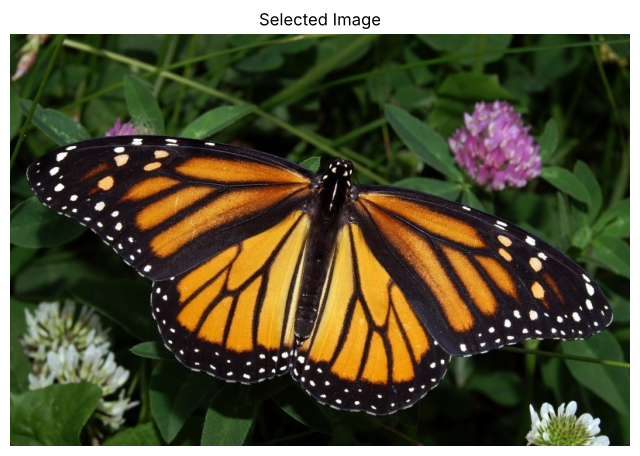

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'Images/butterfly.jpg'

# Load the image, convert to grayscale and blur once (used by all methods)
img = cv2.imread(imgFile)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)   # reduce noise before the derivative filters

print('Image shape:', img.shape)

plt.figure(figsize=(8, 5.5))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Selected Image'), plt.axis('off')
plt.show()

# **Task 1: Apply Edge Detection Methods**

## **Sobel Edge Detector**
The Sobel operator computes the first derivative in x and y with 3×3 kernels that give more weight to the centre row/column:

Gx = [[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]  Gy = [[-1, -2, -1], [0, 0, 0], [1, 2, 1]]

The edge strength is the gradient magnitude **|G| = √(Gx² + Gy²)**.

**Note:** the magnitude can be larger than 255. Converting it with `np.uint8(...)` directly wraps those values around (for example 300 becomes 44), so the strongest edges would turn dark. `np.clip(..., 0, 255)` is used before the conversion.

Max Sobel magnitude: 586.4
Pixels above 255 (would wrap around without clipping): 12958


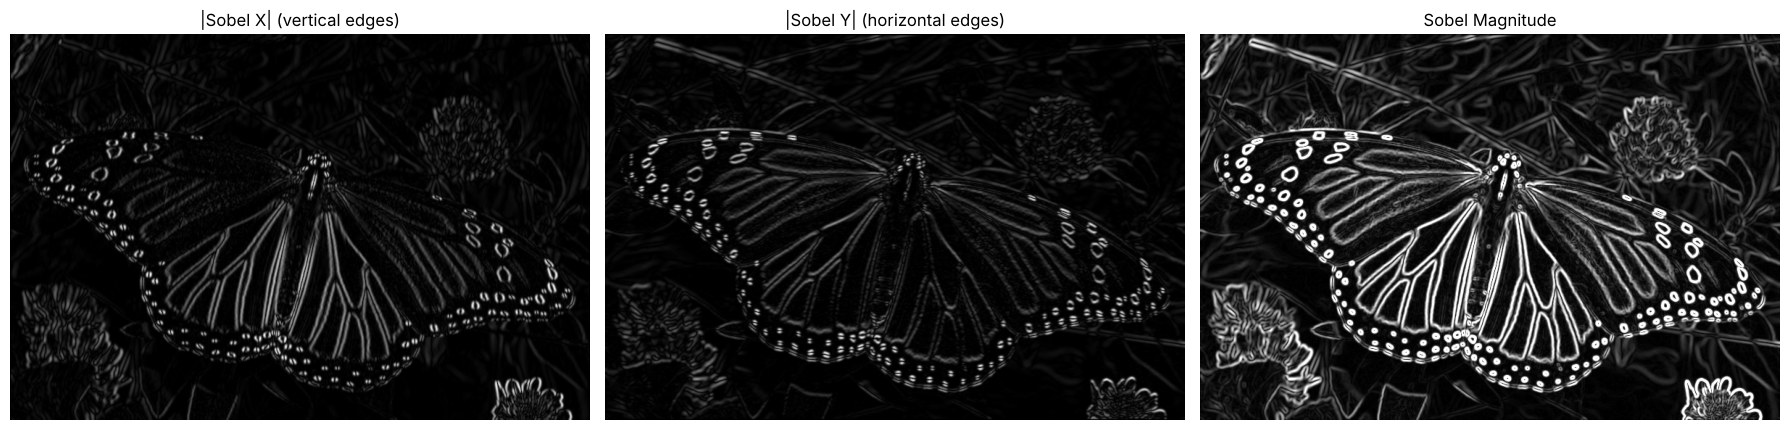

In [2]:
# Apply Sobel filter (CV_64F keeps negative and large derivative values)
sobelx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)

# Magnitude (final edge map), clipped to 0-255 before converting to 8-bit
sobel_combined = cv2.magnitude(sobelx, sobely)
sobel_final = np.uint8(np.clip(sobel_combined, 0, 255))

print('Max Sobel magnitude: %.1f' % sobel_combined.max())
print('Pixels above 255 (would wrap around without clipping):', (sobel_combined > 255).sum())

plt.figure(figsize=(18, 5))
plt.subplot(1, 3, 1), plt.imshow(np.abs(sobelx), cmap='gray'), plt.title('|Sobel X| (vertical edges)')
plt.subplot(1, 3, 2), plt.imshow(np.abs(sobely), cmap='gray'), plt.title('|Sobel Y| (horizontal edges)')
plt.subplot(1, 3, 3), plt.imshow(sobel_final, cmap='gray'), plt.title('Sobel Magnitude')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout(); plt.show()

## **Prewitt Edge Detector**
Prewitt is also a first-derivative operator, but all three rows/columns have the **same weight**:

Gx = [[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]]  Gy = [[-1, -1, -1], [0, 0, 0], [1, 1, 1]]

OpenCV has no built-in Prewitt function, so the kernels are applied with `cv2.filter2D`.

Max Prewitt magnitude: 438.7


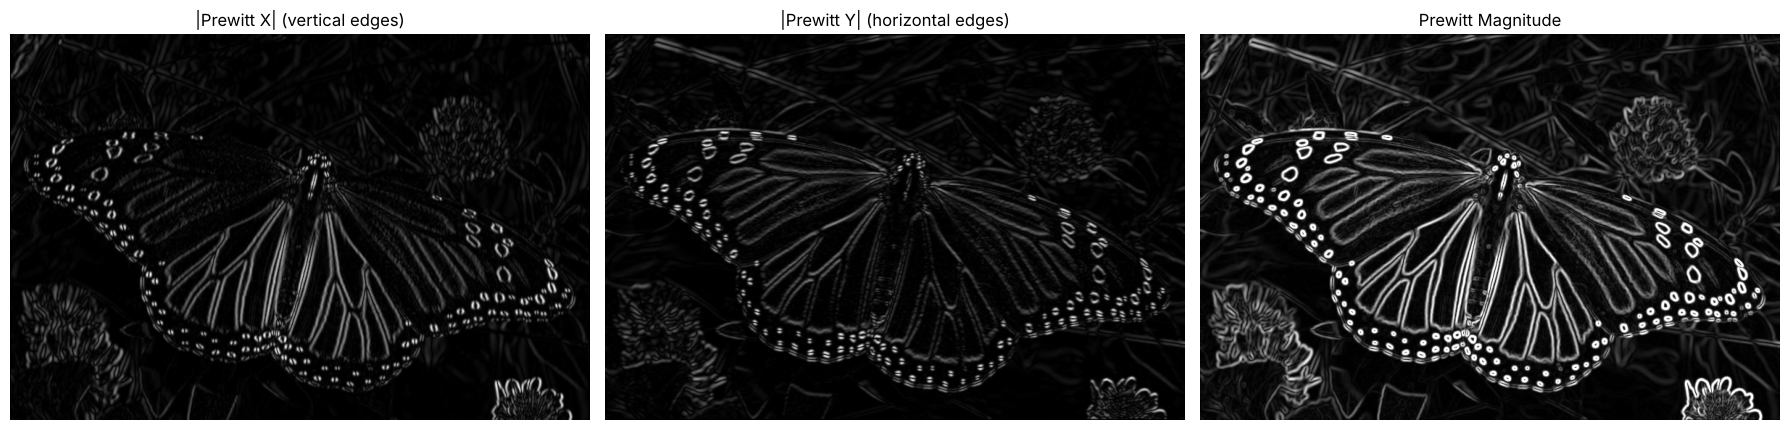

In [3]:
# Define Prewitt Kernels manually
kernel_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float64)
kernel_y = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float64)

# Apply filters
prewitt_x = cv2.filter2D(blurred, cv2.CV_64F, kernel_x)
prewitt_y = cv2.filter2D(blurred, cv2.CV_64F, kernel_y)

# Magnitude, clipped to 0-255 before converting to 8-bit
prewitt_combined = cv2.magnitude(prewitt_x, prewitt_y)
prewitt_final = np.uint8(np.clip(prewitt_combined, 0, 255))

print('Max Prewitt magnitude: %.1f' % prewitt_combined.max())

plt.figure(figsize=(18, 5))
plt.subplot(1, 3, 1), plt.imshow(np.abs(prewitt_x), cmap='gray'), plt.title('|Prewitt X| (vertical edges)')
plt.subplot(1, 3, 2), plt.imshow(np.abs(prewitt_y), cmap='gray'), plt.title('|Prewitt Y| (horizontal edges)')
plt.subplot(1, 3, 3), plt.imshow(prewitt_final, cmap='gray'), plt.title('Prewitt Magnitude')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout(); plt.show()

## **Canny Edge Detector**
Canny is a multi-stage algorithm: Gaussian smoothing, Sobel gradient, **non-maximum suppression** (keeps only the thinnest line along each edge) and **hysteresis thresholding** with a low and a high threshold. The result is a binary map of thin, connected edges.

The thresholds 100 and 200 from the reference notebook are used here (a 1:2 ratio).

Edge pixels: 26682 (6.27% of the image)


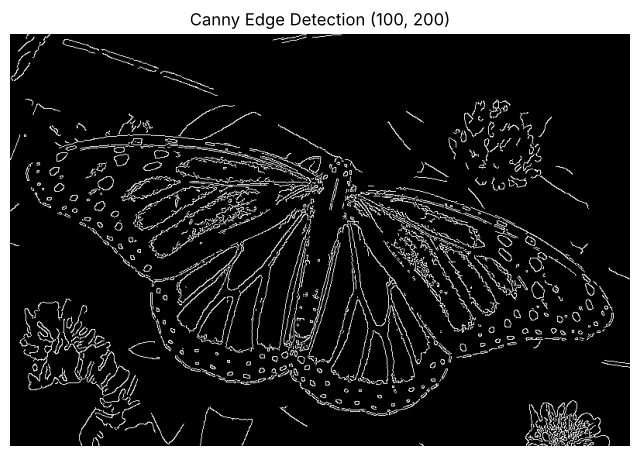

In [4]:
# Syntax: cv2.Canny(image, low_threshold, high_threshold)
canny_edges = cv2.Canny(gray, 100, 200)

print('Edge pixels:', np.count_nonzero(canny_edges),
      '(%.2f%% of the image)' % (100 * np.count_nonzero(canny_edges) / canny_edges.size))

plt.figure(figsize=(8, 5.5))
plt.imshow(canny_edges, cmap='gray'), plt.title('Canny Edge Detection (100, 200)'), plt.axis('off')
plt.show()

## **Original Image and the Three Edge Maps**

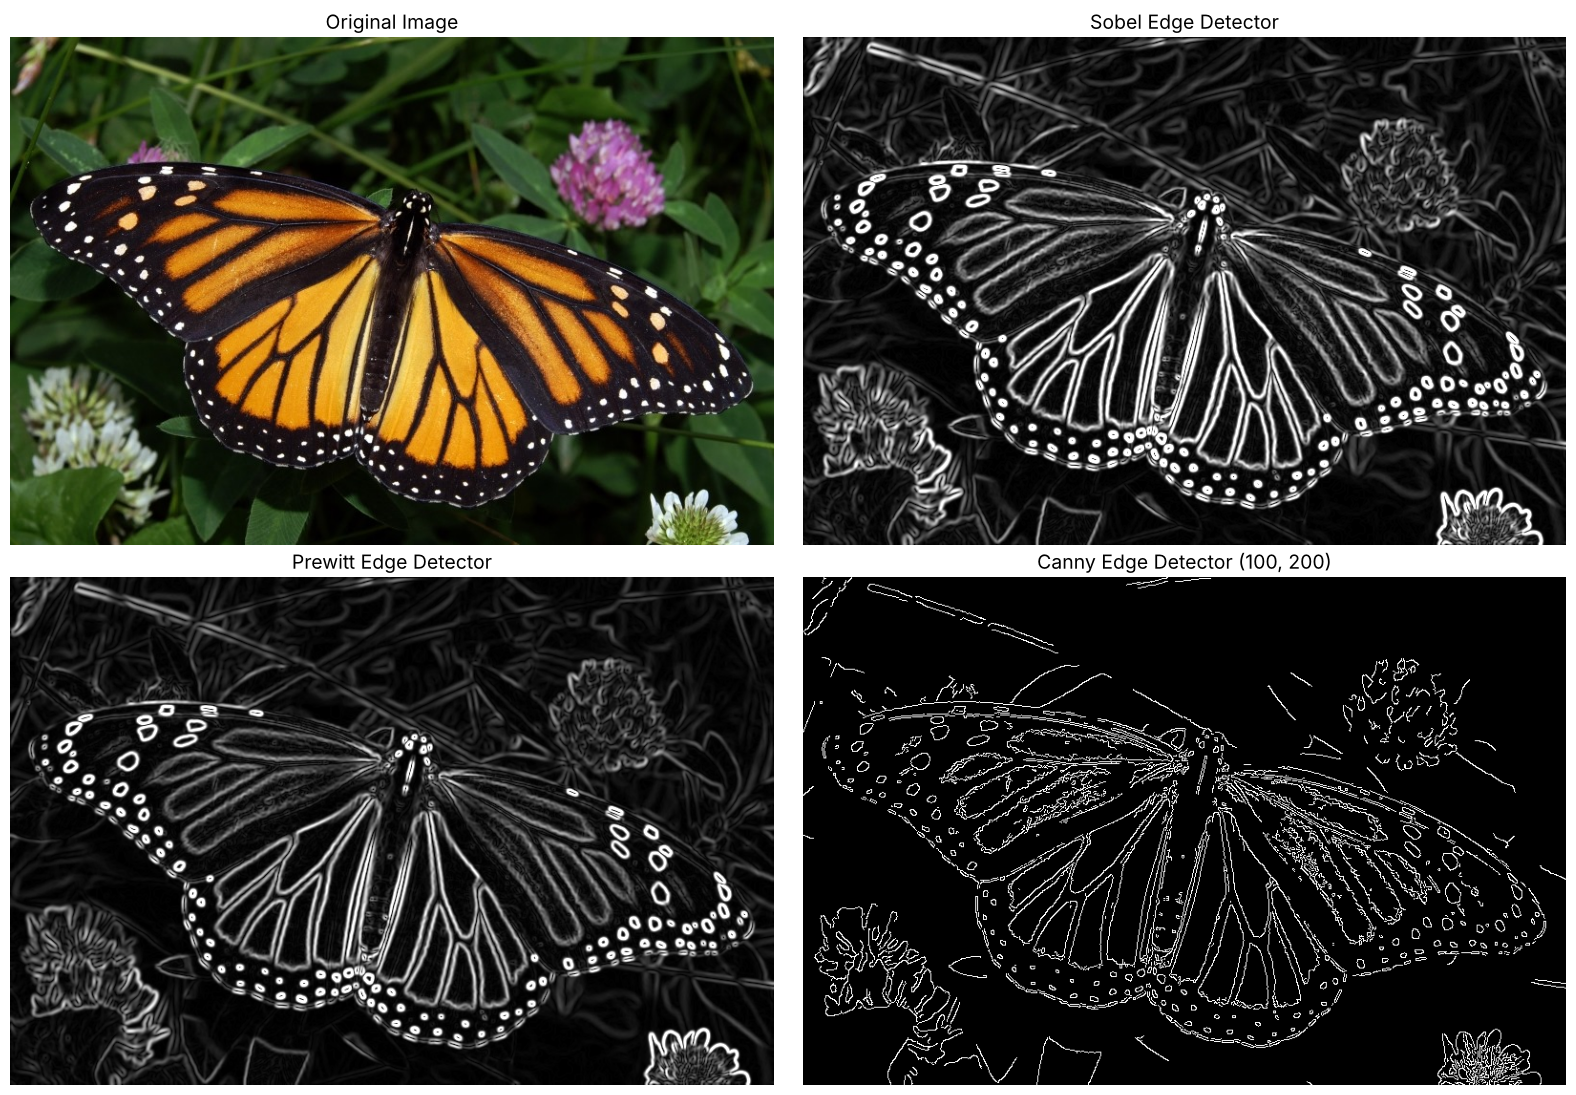

In [5]:
plt.figure(figsize=(16, 11))
plt.subplot(2, 2, 1), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Original Image', fontsize=14)
plt.subplot(2, 2, 2), plt.imshow(sobel_final, cmap='gray'),   plt.title('Sobel Edge Detector', fontsize=14)
plt.subplot(2, 2, 3), plt.imshow(prewitt_final, cmap='gray'), plt.title('Prewitt Edge Detector', fontsize=14)
plt.subplot(2, 2, 4), plt.imshow(canny_edges, cmap='gray'),   plt.title('Canny Edge Detector (100, 200)', fontsize=14)
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout(); plt.show()

In [6]:
# Compare Sobel and Prewitt numerically
print('Mean gradient magnitude  Sobel  : %.2f' % sobel_combined.mean())
print('Mean gradient magnitude  Prewitt: %.2f' % prewitt_combined.mean())
print('Ratio Sobel / Prewitt          : %.2f' % (sobel_combined.mean() / prewitt_combined.mean()))

Mean gradient magnitude  Sobel  : 48.71
Mean gradient magnitude  Prewitt: 36.35
Ratio Sobel / Prewitt          : 1.34


**Observations (Task 1):**
- **Sobel** and **Prewitt** give very similar grey-level edge maps: the wing borders, the black veins and the white dots are all visible, and the strength of each edge is shown by its brightness. Sobel's response is about 4/3 times stronger (ratio printed above), because its kernel gives weight 2 to the centre row/column (sum of positive weights 4 instead of 3). Its extra centre weight also gives slightly better smoothing and less noise.
- Both gradient methods produce **thick edges** and also respond weakly to the texture of the leaves in the background, because they show every intensity change, not only the real edges.
- **Canny** gives a **binary map with thin (one-pixel), continuous edges**. Non-maximum suppression removes the thick edge response, and hysteresis removes many of the weak background responses, so the butterfly outline, veins and dots stand out clearly, with only some leaf and flower edges left in the background. This makes Canny the cleanest result of the three.

# **Task 2: Investigate the Effect of Canny Thresholds**

Canny uses two thresholds on the gradient magnitude:
- pixels **above High** are strong edges and are always kept;
- pixels **below Low** are discarded;
- pixels **between Low and High** are kept **only if they are connected** to a strong edge (hysteresis).

Three threshold pairs are applied: (30, 90) and (50, 150) use a 1:3 ratio, and (100, 200) uses a 1:2 ratio.

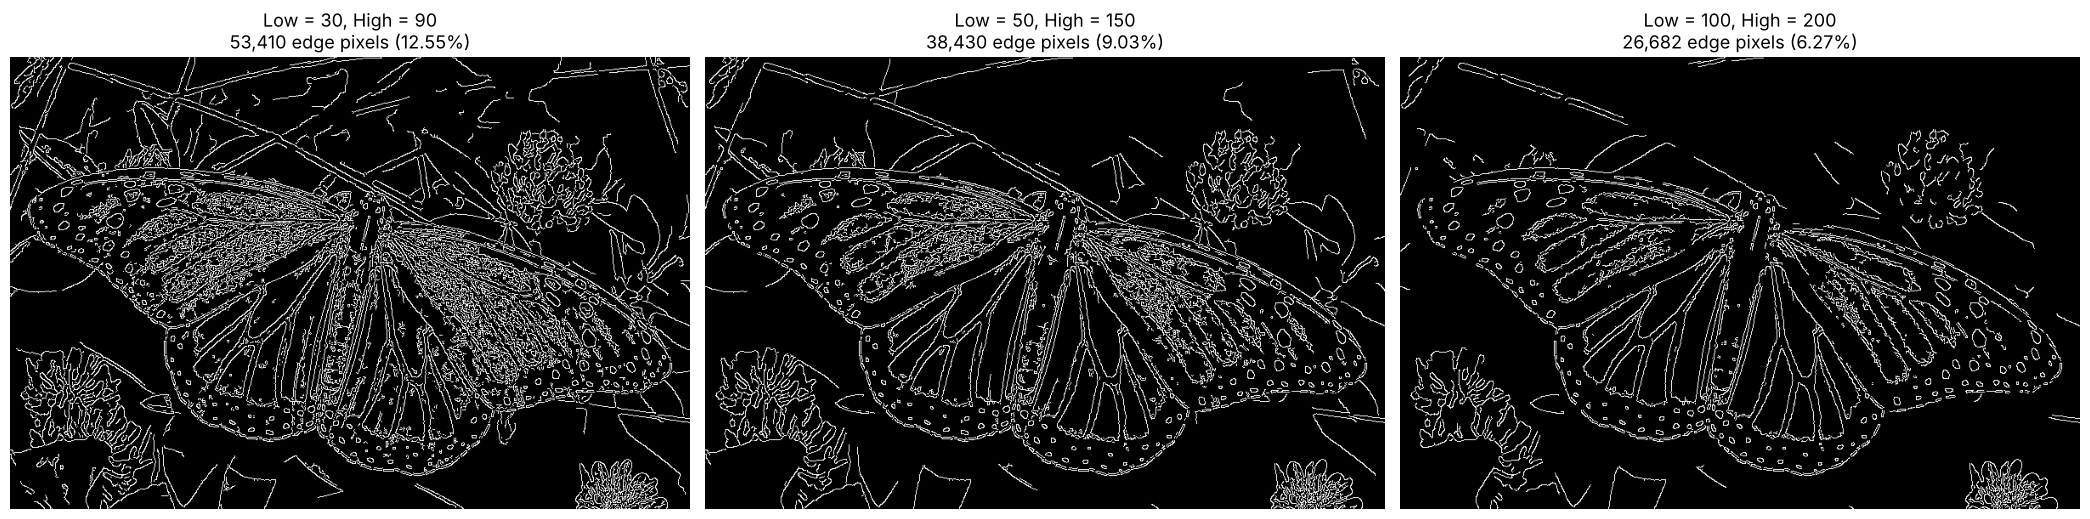

  Thresholds | Edge pixels | % of image
----------------------------------------
    (30, 90) |      53,410 |     12.55%
   (50, 150) |      38,430 |      9.03%
  (100, 200) |      26,682 |      6.27%


In [7]:
threshold_pairs = [(30, 90), (50, 150), (100, 200)]
canny_results = {}

plt.figure(figsize=(21, 6))
for i, (low, high) in enumerate(threshold_pairs, start=1):
    edges = cv2.Canny(gray, low, high)
    canny_results[(low, high)] = edges
    n = np.count_nonzero(edges)
    plt.subplot(1, 3, i)
    plt.imshow(edges, cmap='gray')
    plt.title(f'Low = {low}, High = {high}\n{n:,} edge pixels ({100 * n / edges.size:.2f}%)', fontsize=13)
    plt.axis('off')
plt.tight_layout(); plt.show()

print(f'{"Thresholds":>12} | {"Edge pixels":>11} | {"% of image":>10}')
print('-' * 40)
for (low, high), edges in canny_results.items():
    n = np.count_nonzero(edges)
    print(f'{f"({low}, {high})":>12} | {n:>11,} | {100 * n / edges.size:>9.2f}%')

### Zoom on part of the wing and the background
The crop below makes the difference in small details easier to see.

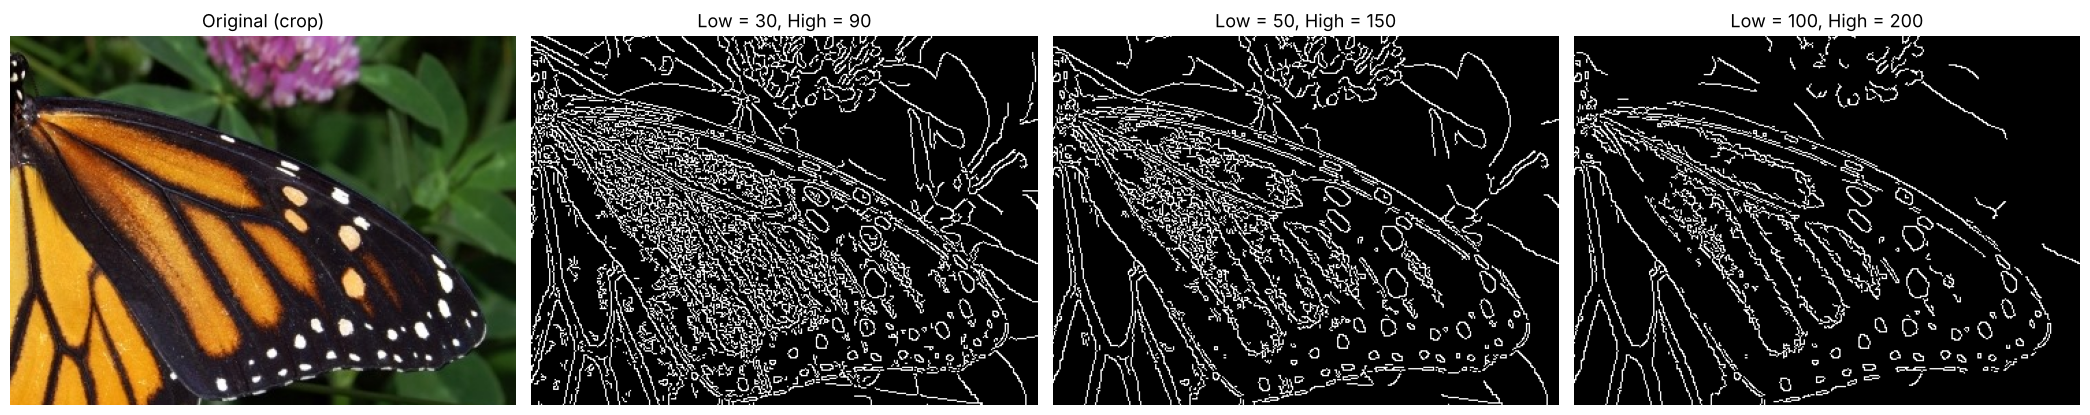

In [8]:
# Region with the right wing, white dots and part of the leaves
y0, y1, x0, x1 = 150, 420, 430, 800

plt.figure(figsize=(21, 6.5))
plt.subplot(1, 4, 1), plt.imshow(cv2.cvtColor(img[y0:y1, x0:x1], cv2.COLOR_BGR2RGB)), plt.title('Original (crop)', fontsize=13)
for i, ((low, high), edges) in enumerate(canny_results.items(), start=2):
    plt.subplot(1, 4, i), plt.imshow(edges[y0:y1, x0:x1], cmap='gray'), plt.title(f'Low = {low}, High = {high}', fontsize=13)
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout(); plt.show()

### Explanation: how the thresholds affect the result

**Number of detected edges.** The number of edge pixels drops as the thresholds increase (see the table above). With **Low = 30, High = 90** many pixels pass the high threshold and many weak pixels are connected through the low threshold, so the most edges are detected. With **Low = 100, High = 200** only strong gradients are accepted, so the fewest edges remain.

**Visibility of details.**
- **(30, 90) – low thresholds:** the most detail is visible. All the white dots, veins and the outline are detected, but so is the fine scale texture inside the orange parts of the wings (many small broken lines, clearly visible in the zoom) and many weak edges from the leaves, grass stems and flowers in the background. The edge map looks busy, and these texture edges make the main shapes harder to see.
- **(50, 150) – medium thresholds:** a good balance. The outline, veins and dots are still complete, many of the background leaf edges are gone, and the texture inside the orange areas is reduced but still partly visible.
- **(100, 200) – high thresholds:** only the strongest edges remain: the wing outline, the black veins and the white dots, which have high contrast with the black border. The orange areas become almost clean. The result is the clearest, but weaker edges start to break or disappear, for example the grass stem across the top of the image becomes a dashed line and several leaf edges are lost.

**Summary:** lower thresholds give **more edges and more detail, but also more noise**; higher thresholds give **fewer, cleaner edges but lose fine detail**. The threshold pair should be chosen according to the image and the goal: (50, 150) works best for this image because it keeps the butterfly's details while removing much of the background texture.

# **Conclusion**
- **Sobel** and **Prewitt** are first-derivative (gradient) operators that give thick, grey-level edge maps. Sobel gives a slightly stronger and smoother response because of its weighted centre.
- **Canny** gives thin, connected, binary edges and suppresses most noise, so it gives the clearest edge map.
- In Canny, the **low and high thresholds** control the trade-off between detail and noise: lower thresholds detect more edges (including noise and texture), higher thresholds detect only the strongest edges and may miss fine details.